## Part A

#### 1. What are Supervised Learning Algorithms?

Supervised learning is a type of Machine Learning in which a model learns from labelled data containing inputs and their correct outputs. It identifies patterns in the data and uses them to predict outputs for new data. Examples include Linear Regression, Logistic Regression, and Decision Tree.

#### 2. Difference between Regression and Classification Algorithms

Regression predicts continuous numerical values, such as salary, house prices, or temperature. Classification predicts categories, such as pass/fail, spam/not spam, or disease/no disease. Regression algorithms are evaluated using MAE and MSE, while classification algorithms use accuracy, precision, and recall.

#### 3. Explain Simple Linear Regression

Simple Linear Regression is a supervised learning algorithm that predicts a numerical value using one independent variable. It finds the best-fit straight line between the input and output variables. Its formula is Y = mX + c, where Y is the predicted value, X is the input, m is the slope, and c is the intercept. For example, it can predict a student's marks based on study hours.

#### 4. List and Explain the Assumptions of Linear Regression

The main assumptions of Linear Regression are:

1. Linearity: There should be a linear relationship between the input and output variables.
2. Normality: The errors should be approximately normally distributed.
3. No Multicollinearity: Independent variables should not be highly correlated with each other.
4. Homoscedasticity: The variance of errors should remain approximately constant.
5. No Autocorrelation: Errors should not be correlated with one another.
6. Independence: Observations should be independent of each other.

These assumptions help ensure that the model's estimates and statistical results are reliable.

#### 5. What is Bias–Variance Trade-Off?

Bias–Variance Trade-Off is the process of balancing bias and variance to build a model that performs well on unseen data. High bias occurs when a model is too simple and may cause underfitting, while high variance occurs when a model is too sensitive to training data and may cause overfitting. The main goal is to find the right model complexity for accurate predictions.

#### 6. Explain Overfitting and Underfitting with Examples

Overfitting: Overfitting occurs when a model learns the training data too closely, including noise and unnecessary details. It gives good results on training data but performs poorly on new data. For example, a Decision Tree memorizes training examples but makes incorrect predictions on unseen examples.

Underfitting: Underfitting occurs when a model is too simple to learn the important patterns in the data. It performs poorly on both training and testing data. For example, using a straight line to predict a complex curved relationship may lead to underfitting.



## Part B

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/RealEstate_HousePrice_Dataset_4200 - RealEstate_HousePrice_Dataset_4200.csv.csv")
df

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566
...,...,...,...,...,...,...,...,...,...,...,...,...
4195,104196,1328,4,2,4.9,21,19.6,2606,1,0,21,18319188
4196,104197,2363,6,4,6.9,53,24.9,4013,1,0,14,40340976
4197,104198,632,2,2,4.5,27,19.4,1268,1,0,6,5978595
4198,104199,450,2,2,7.5,26,11.6,800,0,0,9,7916191


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   house_id              4200 non-null   int64  
 1   area_sqft             4200 non-null   int64  
 2   bedrooms              4200 non-null   int64  
 3   bathrooms             4200 non-null   int64  
 4   location_score        4200 non-null   float64
 5   age_years             4200 non-null   int64  
 6   distance_city_km      4200 non-null   float64
 7   lot_size_sqft         4200 non-null   int64  
 8   has_garage            4200 non-null   int64  
 9   has_pool              4200 non-null   int64  
 10  renovation_years_ago  4200 non-null   int64  
 11  house_price_inr       4200 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 393.9 KB


In [4]:
df.describe()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
count,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4.200000e+03
mean,102100.500000,1667.357381,3.696667,2.827381,5.611429,23.829524,18.186167,3366.329048,0.642381,0.096190,7.955714,2.364189e+07
std,1212.579894,630.336132,1.574199,1.153585,2.140880,13.945663,8.674549,1658.230565,0.479356,0.294887,7.316766,1.239279e+07
min,100001.000000,450.000000,1.000000,1.000000,1.000000,1.000000,1.000000,800.000000,0.000000,0.000000,0.000000,8.000000e+05
25%,101050.750000,1226.750000,3.000000,2.000000,4.000000,13.000000,11.800000,2122.500000,0.000000,0.000000,2.000000,1.425969e+07
50%,102100.500000,1660.000000,4.000000,3.000000,5.700000,21.000000,17.800000,3188.000000,1.000000,0.000000,6.000000,2.214500e+07
75%,103150.250000,2084.250000,5.000000,4.000000,7.300000,32.000000,24.200000,4364.250000,1.000000,0.000000,12.000000,3.096090e+07
max,104200.000000,4202.000000,7.000000,6.000000,10.000000,80.000000,47.600000,12938.000000,1.000000,1.000000,50.000000,7.611172e+07


In [5]:
## Scaling

from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

for col in df.columns:
  df[col]=scaler.fit_transform(df[[col]])

df.drop("house_id",axis=1,inplace=True)
df

,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,0.484946,0.828033,1.016621,0.928968,-0.059490,-0.724754,1.117994,0.746129,-0.326233,-1.087456,1.342327
1,-0.170338,-0.442606,0.149655,0.321668,-0.776644,-0.275109,0.311014,0.746129,-0.326233,0.689497,0.255836
2,0.640437,0.192714,0.149655,0.088092,-1.063505,0.335946,0.676507,-1.340251,-0.326233,0.142742,0.457885
3,1.543238,0.828033,0.149655,0.975683,-0.848359,-1.185928,0.149376,0.746129,3.065296,-0.540701,1.942577
4,-0.268710,-0.442606,0.149655,-0.846215,-0.633213,0.670297,-0.424195,-1.340251,-0.326233,0.962874,-0.477538
...,...,...,...,...,...,...,...,...,...,...,...
4195,-0.538439,0.192714,-0.717311,-0.332346,-0.202920,0.163006,-0.458573,0.746129,-0.326233,1.783006,-0.429551
4196,1.103737,1.463352,1.016621,0.601960,2.091973,0.774061,0.390023,0.746129,-0.326233,0.826185,1.347645
4197,-1.642744,-1.077925,-0.717311,-0.519208,0.227372,0.139947,-1.265553,0.746129,-0.326233,-0.267324,-1.425458
4198,-1.931513,-1.077925,-0.717311,0.882252,0.155657,-0.759342,-1.547815,-1.340251,-0.326233,0.142742,-1.269091


In [6]:
x=df[["area_sqft"]]
y=df['house_price_inr']

In [7]:
x  ## Independent variables

,area_sqft
0,0.484946
1,-0.170338
2,0.640437
3,1.543238
4,-0.268710
...,...
4195,-0.538439
4196,1.103737
4197,-1.642744
4198,-1.931513


In [8]:
y ## Dependent /Target variable

,house_price_inr
0,1.342327
1,0.255836
2,0.457885
3,1.942577
4,-0.477538
...,...
4195,-0.429551
4196,1.347645
4197,-1.425458
4198,-1.269091


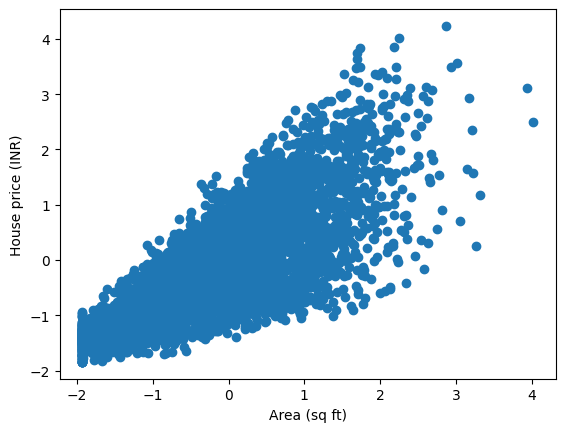

In [9]:
## Relation between features and target variable

plt.scatter(x,y)
plt.xlabel("Area (sq ft)")
plt.ylabel("House price (INR)")
plt.show()

In [10]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

## Part C

In [11]:
from sklearn.linear_model import LinearRegression

lr=LinearRegression()
lr.fit(x_train,y_train)

LinearRegression()

In [12]:
print("Slope:", lr.coef_[0])
print("Intercept:", lr.intercept_)

Slope: 0.7521797989302733
Intercept: -0.011945002946086221


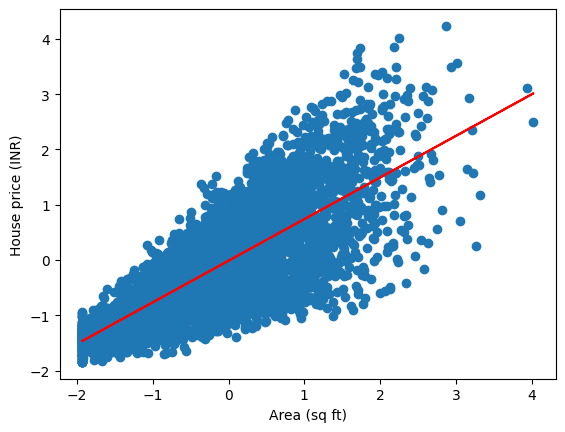

In [13]:
import matplotlib.pyplot as plt

plt.scatter(x, y)
plt.plot(x, lr.predict(x), color="red")
plt.xlabel("Area (sq ft)")
plt.ylabel("House price (INR)")
plt.show()

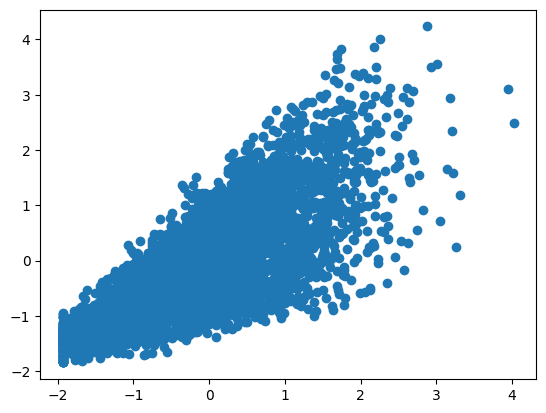

In [14]:
## Assumptions

## 1.Linearity
plt.scatter(x,y)

<Axes: xlabel='house_price_inr', ylabel='Count'>

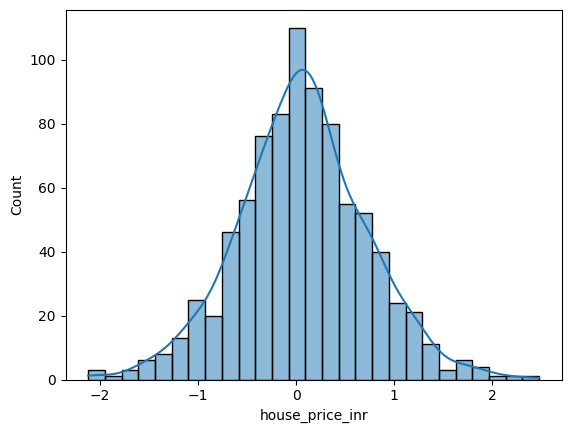

In [15]:
## Normality
y_pred=lr.predict(x_test)
error=y_test-y_pred
sns.histplot(error,kde=True)


## Part D

In [16]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,root_mean_squared_error,r2_score

In [17]:
mean_squared_error(y_test,y_pred)

0.4362853794432436

In [18]:
mean_absolute_error(y_test,y_pred)

0.507984477719102

In [19]:
root_mean_squared_error(y_test,y_pred)

0.6605190227716713

In [20]:
r2=r2_score(y_test,y_pred)
print(r2)

0.5625199587991578


In [21]:
n = len(y)
k = x.shape[1]
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - k - 1)
print("Adjusted R2:", adj_r2)

Adjusted R2: 0.5624157472600437


In [21]:
"""
MSE = 0.4363. This is the average squared error. It is high, so predictions
are far off. It is mainly useful for comparing models.

MAE = 0.5080. Predictions are off by about 0.51 standard deviations
of price on average, roughly ₹6.3M.

RMSE = 0.6605. The typical error is about 0.66 standard deviations,
roughly ₹8.2M. It is higher than MAE, so some errors are large.

R² = 0.5625. Area explains about 56% of the variation in price. The other
44% is unexplained.

Adjusted R² = 0.5624. It is almost the same as R², so area is a genuinely
useful feature.
"""

## Part E


In [22]:
x=df.drop("house_price_inr",axis=1)
y=df['house_price_inr']

In [23]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [24]:
lin=LinearRegression()
lin.fit(x_train,y_train)

LinearRegression()

In [25]:
y_pred=lin.predict(x_test)

In [26]:
print("Slope:", lin.coef_)
print("Intercept:", lin.intercept_)

Slope: [ 0.70170512  0.0251057   0.01730868  0.5308971  -0.0738304  -0.06927241
  0.01384971  0.00363302  0.01083367 -0.01265588]
Intercept: 0.0011429084100363796


In [27]:
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

Mean Squared Error: 0.08201473477789782


In [28]:
mean_absolute_error(y_test,y_pred)

0.21022726212367374

In [29]:
root_mean_squared_error(y_test,y_pred)

0.28638214814806073

In [30]:
r2=r2_score(y_test,y_pred)
print(r2)

0.9177606877509896


In [31]:
adj_r2 = 1 - (1 - r2) * (len(y) - 1) / (len(y) - x.shape[1] - 1)
print("Adjusted R2:", adj_r2)

Adjusted R2: 0.9175643656878504


In [31]:
## Why performance improves

"""
Performance improves a lot with multiple regression:
-RMSE falls from 0.661 to 0.286.
-R² rises from 0.5625 to 0.9178.

Reasons:
-More information: Simple regression uses only area, so it explains
ust 56% of the price variation. Multiple regression adds the other
features and explains about 92%.

-Strong extra features: location_score (coefficient 0.53) matters
almost as much as area (0.70). age_years (-0.07) and distance_city_km (-0.07)
lower the price.

-No overfitting: Adjusted R² (0.9176) is almost equal to R² (0.9178),
so the added features are genuinely useful.

"""


## Part F

In [32]:
from sklearn.preprocessing import PolynomialFeatures
poly=PolynomialFeatures(degree=2)
x_poly=poly.fit_transform(x)
x_test_poly=poly.transform(x_test)
x_train_poly=poly.transform(x_train)


In [33]:
pr=LinearRegression()
pr.fit(x_poly,y)

LinearRegression()

In [34]:
y_pred_poly=pr.predict(x_test_poly)


In [46]:
print("Linear     | Train R2:", r2_score(y_train, lin.predict(x_train)),
      "| Test R2:", r2_score(y_test, lin.predict(x_test)),
      "| Test RMSE:", root_mean_squared_error(y_test, lin.predict(x_test)))

print("Polynomial | Train R2:", r2_score(y_train, pr.predict(x_train_poly)),
      "| Test R2:", r2_score(y_test, pr.predict(x_test_poly)),
      "| Test RMSE:", root_mean_squared_error(y_test, pr.predict(x_test_poly)))

Linear     | Train R2: 0.9247216651865339 | Test R2: 0.9177606877509896 | Test RMSE: 0.28638214814806073
Polynomial | Train R2: 0.9683397053764449 | Test R2: 0.9674934051502285 | Test RMSE: 0.1800495112181464


## Gradient Descent

In [36]:
## Gradient descent

"""
Gradient Descent is an optimization algorithm used in machine
Learning to minimize the error of a model.It works by calculating the
Difference between actual and predicted values.
Then, it updates the model's weights and biases to reduce the error.
This process is repeated until the error is minimized.It helps the model
learn from the data and make accurate predictions.
"""


"\nGradient Descent is an optimization algorithm used in machine \nLearning to minimize the error of a model.It works by calculating the \nDifference between actual and predicted values. \nThen, it updates the model's weights and biases to reduce the error.\nThis process is repeated until the error is minimized.It helps the model \nlearn from the data and make accurate predictions.\n"

In [37]:
## stochastic
from sklearn.linear_model import SGDRegressor

batch=SGDRegressor(max_iter=1000,learning_rate="constant",eta0=0.01,random_state=42)
batch.fit(x_train,y_train)

SGDRegressor(learning_rate='constant', random_state=42)

In [38]:
print("Slope:", batch.coef_[0])
print("Intercept:", batch.intercept_[0])
print("Test R2:", r2_score(y_test, batch.predict(x_test)))
print("Teat MSE:", mean_squared_error(y_test, batch.predict(x_test)))

Slope: 0.6966539590908579
Intercept: -0.026004463893228746
Test R2: 0.914787771710667
Teat MSE: 0.08497953243848314


In [48]:
## Mini Batch
mb = SGDRegressor(learning_rate="constant", eta0=0.01, random_state=42)

for epoch in range(50):
    idx = np.random.permutation(len(x_train))
    for s in range(0, len(idx), 32):
        b = idx[s:s + 32]
        mb.partial_fit(x_train.iloc[b], y_train.iloc[b])

print("Slope:", mb.coef_[0], "Intercept:", mb.intercept_[0])
print("Test R2:", r2_score(y_test, mb.predict(x_test)))

Slope: 0.7007898283106455 Intercept: -0.029632232983179928
Test R2: 0.9098939534863253


## Part H

In [47]:

print("Simple   | Train RMSE:", root_mean_squared_error(y_train, lr.predict(x_train[["area_sqft"]])),
      "| Test RMSE:", root_mean_squared_error(y_test, lr.predict(x_test[["area_sqft"]])))


print("Multiple | Train RMSE:", root_mean_squared_error(y_train, lin.predict(x_train)),
      "| Test RMSE:", root_mean_squared_error(y_test, lin.predict(x_test)))


print("Poly     | Train RMSE:", root_mean_squared_error(y_train, pr.predict(x_train_poly)),
      "| Test RMSE:", root_mean_squared_error(y_test, pr.predict(x_test_poly)))

Simple   | Train RMSE: 0.654041204475215 | Test RMSE: 0.6605190227716713
Multiple | Train RMSE: 0.2743937949127255 | Test RMSE: 0.28638214814806073
Poly     | Train RMSE: 0.1779494951423435 | Test RMSE: 0.1800495112181464


In [ ]:
## How model complexity affects prediction error

"""
Prediction error has two parts, bias and variance.Complexity pushes
them in opposite directions.
-Low complexity (underfitting): The model is too simple to capture the
real pattern. Bias is high, so both training and test error are high.
-Increasing complexity: The model captures more of the pattern,
so bias falls and both errors drop.
-Too much complexity (overfitting): The model starts fitting noise in
the training data. Variance rises, so training error keeps falling but
test error goes back up.
"""

In [ ]:
## Which model best balances bias and variance

"""
Polynomial regression (degree 2) is the best balance.
-It has the lowest test error (RMSE 0.180) and the highest R² (0.967).
-Its train and test errors are almost equal (0.178 vs 0.180), so it is not overfitting.
-Both errors are low, so it is not underfitting either.

Simple regression has high bias. It uses only area, so it underfits.
Multiple regression is a good baseline but misses curves and interactions
between features.
Higher-degree polynomials (degree 3 and above) start to overfit.
"""

## Summary

In [ ]:
"""
1.Best Performing model
Polynomial regression (degree 2) is the best, with test RMSE 0.180
and R² 0.967. Multiple regression gets RMSE 0.286 and R² 0.918, and
simple regression gets RMSE 0.661 and R² 0.563. It wins because it
uses all features and also captures curves and interactions between
them.

2. Impact of gradient descent
SGD (test R² 0.915) and mini-batch (0.910) came very close to normal
linear regression (0.918). Gradient descent finds nearly the same line,
and it matters mainly for large datasets.

3. Overfitting and underfitting
-Simple regression underfits: train and test error are both high (0.654 and 0.661).
-Multiple and polynomial regression do not overfit: train and test
errors are close (0.178 vs 0.180 for polynomial).

4. Business interpretation
Area and location score drive price the most, while age and distance
from the city lower it. The best model’s typical error is about ₹2.2M,
which is accurate enough for pricing guidance and for spotting over-
or under-priced houses.

"""